# Exploratory Visual Analysis

**Exploratory data analysis (EDA)** uses many quick charts to understand a dataset before modelling or reporting: what the distributions look like, which variables are related, where the outliers and errors are. **seaborn** makes these charts short to write.

**After this lesson you can:**

1. Show distributions with histograms, KDE, ECDF, box and violin plots, and know when each one helps.
2. Show relationships with scatter plots, regression lines and pair plots.
3. Compare groups with colour (`hue`) and facets.
4. Handle **overplotting** with millions of points: alpha, sampling, hexbin and 2-D histograms.

**Data:** Palmer penguins (344 penguins) and NYC yellow taxi trips (3 million trips, January 2024).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

import seaborn as sns

sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})
penguins = pd.read_json(datasets.fetch("penguins.json")).rename(columns=lambda c: c.split(" (")[0].lower().replace(" ", "_"))
penguins = penguins.dropna(subset=["body_mass"])
print("seaborn", sns.__version__, "| penguins:", penguins.shape)
penguins.head(3)

seaborn 0.13.2 | penguins: (342, 7)


,species,island,beak_length,beak_depth,flipper_length,body_mass,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE


## 1. Distributions

| Chart | Shows | Weakness |
| :--- | :--- | :--- |
| histogram | counts per bin | shape depends on the bin width |
| KDE | smooth density | can suggest values that do not exist (smooths over gaps and limits) |
| ECDF | share of values ≤ x | less familiar, but no parameters and exact |
| box plot | median, quartiles, outliers | hides multimodality |
| violin | box + KDE | same smoothing issues as KDE |

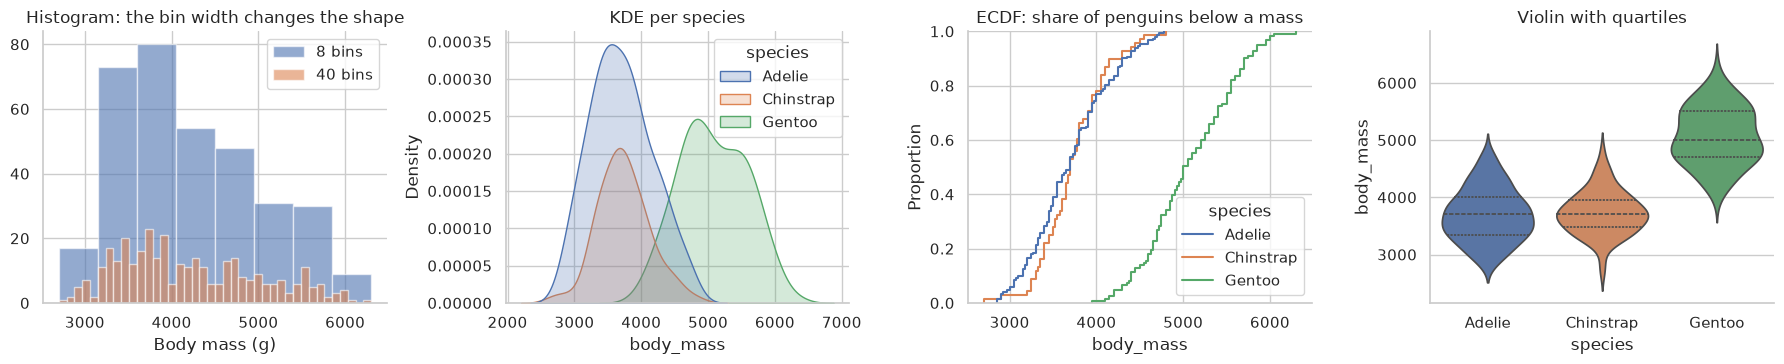

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for bins, alpha in [(8, 0.6), (40, 0.6)]:
    axes[0].hist(penguins["body_mass"], bins=bins, alpha=alpha, label=f"{bins} bins")
axes[0].set(title="Histogram: the bin width changes the shape", xlabel="Body mass (g)")
axes[0].legend()
sns.kdeplot(data=penguins, x="body_mass", hue="species", fill=True, ax=axes[1])
axes[1].set(title="KDE per species")
sns.ecdfplot(data=penguins, x="body_mass", hue="species", ax=axes[2])
axes[2].set(title="ECDF: share of penguins below a mass")
sns.violinplot(data=penguins, x="species", y="body_mass", inner="quart", ax=axes[3], hue="species", legend=False)
axes[3].set(title="Violin with quartiles")
plt.tight_layout()
plt.show()

The single histogram with 40 bins shows two peaks, which a box plot would hide: the heavy Gentoo penguins form their own group. The KDE and ECDF by species confirm it.

## 2. Relationships

A scatter plot with a regression line shows the direction and strength of a relationship. Colouring by group can reveal that one overall trend is really several group trends, or the opposite (Simpson's paradox).

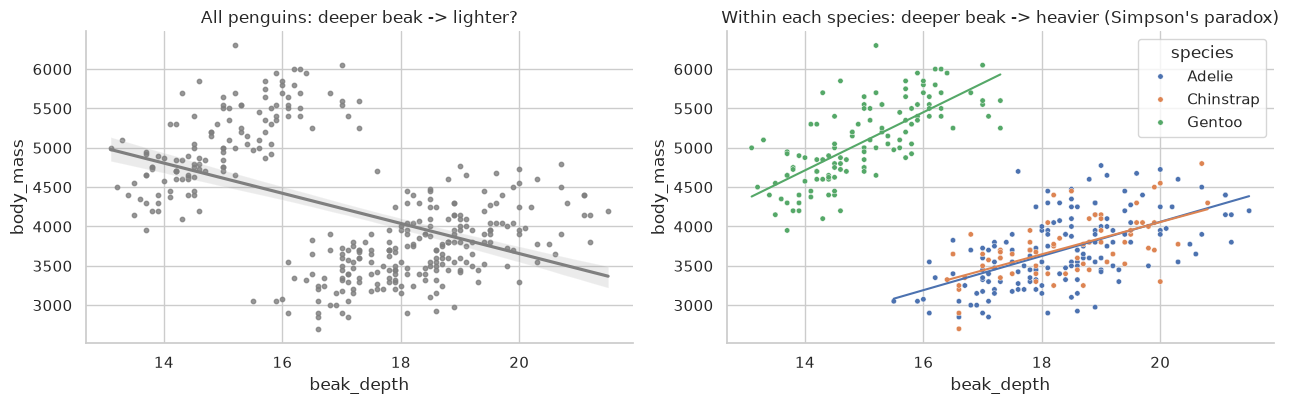

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.regplot(data=penguins, x="beak_depth", y="body_mass", ax=axes[0], scatter_kws={"s": 10}, color="#7F7F7F")
axes[0].set(title="All penguins: deeper beak -> lighter?")
sns.scatterplot(data=penguins, x="beak_depth", y="body_mass", hue="species", s=15, ax=axes[1])
for sp, part in penguins.groupby("species"):
    coef = np.polyfit(part["beak_depth"], part["body_mass"], 1)
    xs = np.linspace(part["beak_depth"].min(), part["beak_depth"].max(), 10)
    axes[1].plot(xs, np.polyval(coef, xs))
axes[1].set(title="Within each species: deeper beak -> heavier (Simpson's paradox)")
plt.tight_layout()
plt.show()

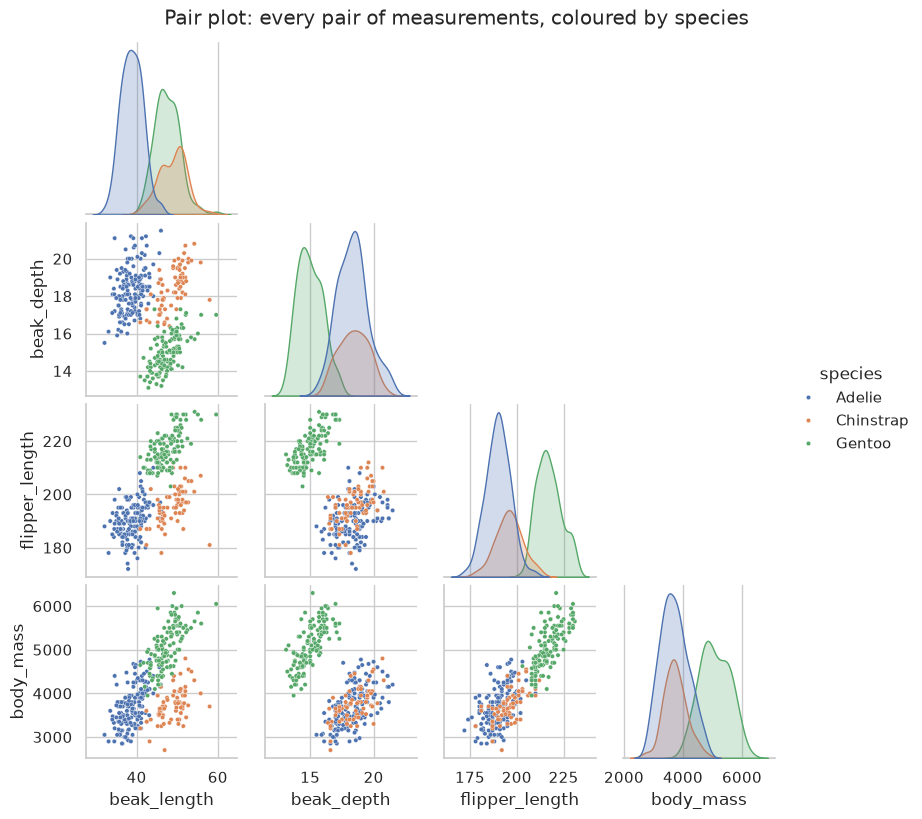

In [4]:
g = sns.pairplot(penguins[["beak_length", "beak_depth", "flipper_length", "body_mass", "species"]], hue="species",
                 corner=True, plot_kws={"s": 10}, height=2.0)
g.figure.suptitle("Pair plot: every pair of measurements, coloured by species", y=1.02)
plt.show()

## 3. Facets: Small Multiples

**Facets** draw the same chart for each group in a grid with shared axes, so the eye compares like with like.

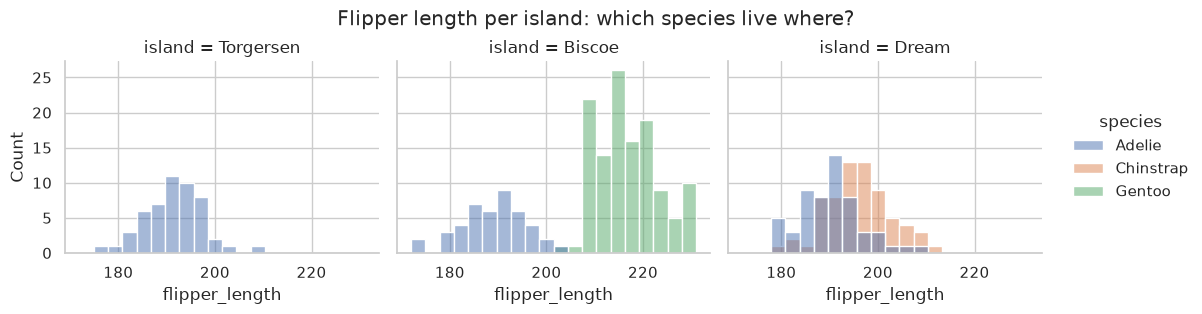

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe         44          0     123
Dream          56         68       0
Torgersen      51          0       0


In [5]:
g = sns.displot(data=penguins, x="flipper_length", col="island", hue="species", kind="hist", height=3, aspect=1.2, bins=20)
g.figure.suptitle("Flipper length per island: which species live where?", y=1.04)
plt.show()
print(pd.crosstab(penguins["island"], penguins["species"]))

## 4. Overplotting with Millions of Points

With 3 million taxi trips, a scatter plot becomes a solid block: the eye cannot see where most points are. Solutions:

1. transparency (`alpha`),
2. a random sample,
3. **hexbin** or **2-D histogram** with a log colour scale (shows density),
4. aggregation before plotting (lines of medians, quantile bands).

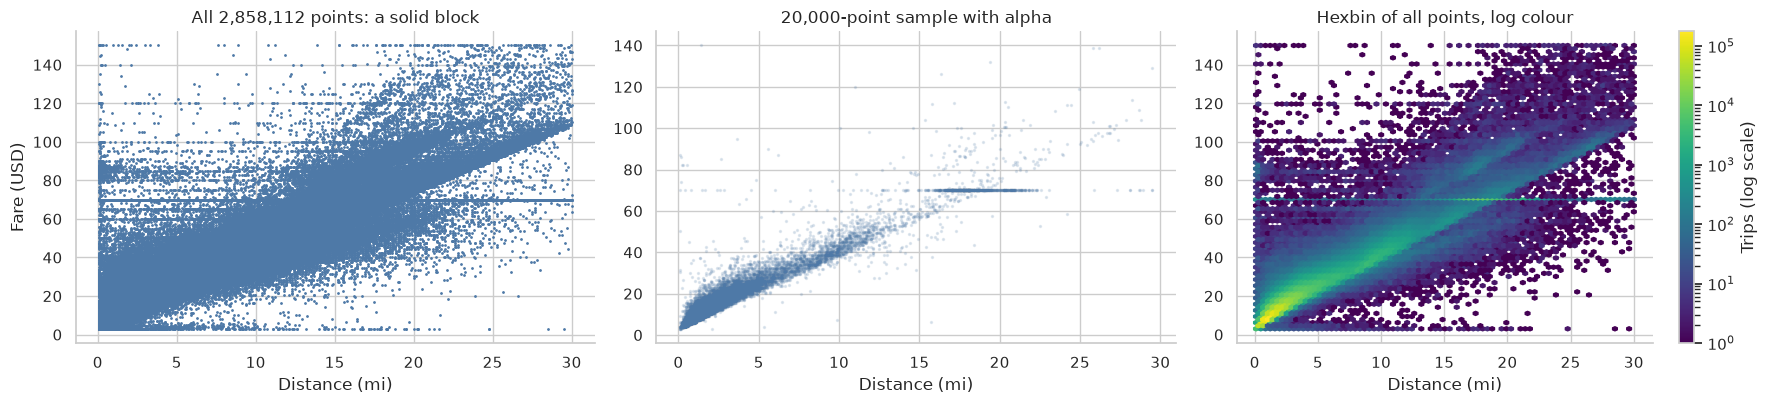

In [6]:
taxi = pd.read_parquet(datasets.taxi("2024-01"), columns=["trip_distance", "fare_amount", "tip_amount", "payment_type"])
taxi = taxi[taxi["trip_distance"].between(0.1, 30) & taxi["fare_amount"].between(3, 150)]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
axes[0].scatter(taxi["trip_distance"], taxi["fare_amount"], s=1, color="#4E79A7")
axes[0].set(title=f"All {len(taxi):,} points: a solid block", xlabel="Distance (mi)", ylabel="Fare (USD)")
sample = taxi.sample(20_000, random_state=0)
axes[1].scatter(sample["trip_distance"], sample["fare_amount"], s=2, alpha=0.15, color="#4E79A7")
axes[1].set(title="20,000-point sample with alpha", xlabel="Distance (mi)")
hb = axes[2].hexbin(taxi["trip_distance"], taxi["fare_amount"], gridsize=80, bins="log", cmap="viridis", mincnt=1)
fig.colorbar(hb, ax=axes[2], label="Trips (log scale)")
axes[2].set(title="Hexbin of all points, log colour", xlabel="Distance (mi)")
plt.tight_layout()
plt.show()

The hexbin reveals the structure that the solid block hides: the main fare-per-mile band, a horizontal line at the flat JFK–Manhattan fare (\$70), and a cloud of short, expensive trips (waiting time and surcharges).

## 5. A Quick EDA Checklist

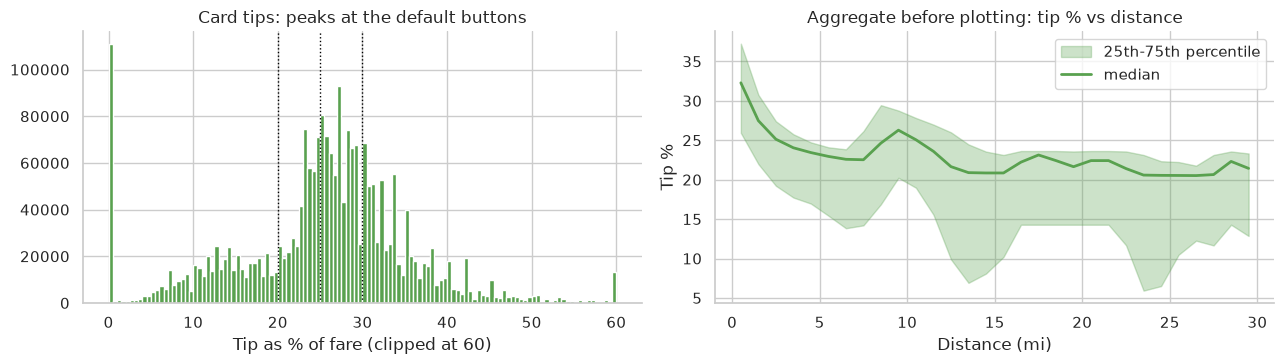

In [7]:
card = taxi[taxi["payment_type"] == 1].assign(tip_pct=lambda d: 100 * d["tip_amount"] / d["fare_amount"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(card["tip_pct"].clip(0, 60), bins=120, color="#59A14F")
axes[0].set(title="Card tips: peaks at the default buttons", xlabel="Tip as % of fare (clipped at 60)")
for p in (20, 25, 30):
    axes[0].axvline(p, color="black", ls=":", lw=1)
band = card.groupby(pd.cut(card["trip_distance"], np.arange(0, 31, 1)), observed=True)["tip_pct"].quantile([0.25, 0.5, 0.75]).unstack()
mids = [iv.mid for iv in band.index]
axes[1].fill_between(mids, band[0.25], band[0.75], alpha=0.3, color="#59A14F", label="25th-75th percentile")
axes[1].plot(mids, band[0.5], color="#59A14F", lw=2, label="median")
axes[1].set(title="Aggregate before plotting: tip % vs distance", xlabel="Distance (mi)", ylabel="Tip %")
axes[1].legend()
plt.tight_layout()
plt.show()

The tip histogram has sharp peaks at the percentages that the payment screen in the taxi suggests: an insight about **how the data is produced**, which a summary table would never show.

| Step | Question |
| :--- | :--- |
| 1 | What is one row? How many rows and columns? |
| 2 | What do the distributions of the key variables look like? Any impossible values? |
| 3 | Which variables are related? Do the relationships hold within groups? |
| 4 | Are there spikes, gaps or round numbers that reveal how the data was recorded? |
| 5 | What questions does the data raise for the next step? |

*Insight: In EDA, draw many quick charts and look for shape, not decimals: multimodality, spikes, gaps and group differences. With large data, show density (hexbin, aggregated bands) instead of raw points.*

## Real-World Use Case or Analogy

EDA is like a **doctor's first examination**: quick, broad checks (temperature, pulse, listening) before any expensive test. Most of the time, they confirm that things are normal; sometimes, they reveal the one problem that changes the whole treatment.

Data scientists often discover data-collection problems in EDA: default values in forms, sensors that report a fixed value when broken, or a payment screen that shapes tipping behaviour, as in this lesson.